<a href="https://colab.research.google.com/github/FrancoPanico/glioblastoma-mri-seg-mgmt/blob/N4ITK/Assignment_Biomedicine_Pipeline_v2_Mattia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Applied AI in Biomedicine — Final Assignment Pipeline (Ottimizzata Anti-Timeout & Risparmio GPU)

**Flusso Operativo Consigliato su Google Colab (Quota GPU Gratuita):**
1. **Fase A — Su Runtime CPU (`Runtime -> Cambia tipo di runtime -> CPU`, consumo GPU = 0):**
   - Esegui **Cella 1 → Cella 2 → Cella 3 → Cella 4 → Cella 4B**.
   - Tutte le celle sono *checkpoint-aware*: saltano automaticamente il training di U-Net e MA-Net se i file `.pth` sono già su Drive, calcolano le metriche 3D del Task 1 (`task1_metrics_comparison.csv`) ed estraggono in modo incrementale su Google Drive (`patient_rois_128.npz`) le ROI `128x128` dei 1.384 pazienti.
2. **Fase B — Su Runtime GPU T4 (`Runtime -> Cambia tipo di runtime -> GPU T4`, ~8-10 minuti totali):**
   - Esegui **Cella 1 → Cella 5 → Cella 6** (leggono istantaneamente `patient_rois_128.npz` da Drive senza più toccare i `.nii.gz`).

## Cella 1: Setup Librerie, Controllo GPU/CPU e Mount Google Drive

In [1]:
!pip install -q segmentation-models-pytorch nibabel albumentations scikit-learn openpyxl

import os
import gc
import random
import psutil
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.ndimage import distance_transform_edt, binary_erosion

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import segmentation_models_pytorch as smp
import albumentations as A

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from google.colab import drive


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def print_ram():
    ram = psutil.virtual_memory()
    print(f"[RAM] Usata: {ram.used / 1e9:.2f} GB / {ram.total / 1e9:.2f} GB ({ram.percent:.1f}%)")


seed_everything(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"Device attivo: {DEVICE} ({torch.cuda.get_device_name(0)})")
else:
    print("Device attivo: CPU (ottimo per Celle 2, 3, 4-Eval e 4B senza consumare quota GPU).")

drive.mount("/content/drive")

CANDIDATE_DIRS = [
    "/content/drive/MyDrive/Applied AI in Biomedicine/assignment",
    "/content/drive/MyDrive/applied AI in biomedicine/assignment",
    "/content/drive/MyDrive/AI_Practical_Sessions_26_27/assignment",
    "/content/drive/MyDrive/assignment",
]
BASE_DIR = next((p for p in CANDIDATE_DIRS if os.path.exists(p)), None)
assert BASE_DIR is not None, (
    "Cartella 'assignment' non trovata su MyDrive. "
    "Aggiorna CANDIDATE_DIRS con il percorso corretto della tua cartella."
)

META_PATH = os.path.join(BASE_DIR, "training_metadata.xlsx")
IMG_DIR = os.path.join(BASE_DIR, "training_images")
OUT_DIR = os.path.join(BASE_DIR, "colab_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

print("BASE_DIR:", BASE_DIR)
print("Metadata trovato:", os.path.exists(META_PATH))
print("Cartella training_images trovata:", os.path.exists(IMG_DIR))
print_ram()

Device attivo: cuda (Tesla T4)
Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/Applied AI in Biomedicine/assignment
Metadata trovato: True
Cartella training_images trovata: True
[RAM] Usata: 2.11 GB / 13.61 GB (17.9%)


## Cella 2: EDA, Indicizzazione Maschere e Stratified 5-Fold Split (Checkpoint-Aware)

In [2]:
SPLIT_CSV = os.path.join(OUT_DIR, "dataset_splits_5fold.csv")

if os.path.exists(SPLIT_CSV):
    df = pd.read_csv(SPLIT_CSV)
    print(f"Split 5-fold già presente su Drive, caricato istantaneamente: {SPLIT_CSV}")
    print(pd.crosstab(df["has_mask"], df["MGMT value"].fillna(-1), margins=True))
else:
    df = pd.read_excel(META_PATH, sheet_name="Sheet1")

    has_all_mri = []
    has_mask = []
    unique_mask_labels = set()

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Indicizzazione pazienti"):
        pid = str(int(row["ID"]))
        p_folder = os.path.join(IMG_DIR, pid)
        mri_ok = all(
            os.path.exists(os.path.join(p_folder, f"{mod}.nii.gz"))
            for mod in ["t1", "t1ce", "t2", "flair"]
        )
        seg_path = os.path.join(p_folder, "seg.nii.gz")
        seg_ok = os.path.exists(seg_path)
        has_all_mri.append(mri_ok)
        has_mask.append(seg_ok)

        if seg_ok and len(unique_mask_labels) < 10 and idx < 50:
            vals = np.unique(nib.load(seg_path).get_fdata()).astype(int)
            unique_mask_labels.update(vals.tolist())

    df["has_all_mri"] = has_all_mri
    df["has_mask"] = has_mask

    print("\n--- Riepilogo Disponibilità Annotazioni ---")
    print(pd.crosstab(df["has_mask"], df["MGMT value"].fillna(-1), margins=True))
    print("Valori unici rilevati nelle maschere ground-truth:", sorted(unique_mask_labels))

    # Stratified 5-Fold a livello di paziente (anti data leakage)
    cohort_strat = df["Cohort ID"].replace({1: 2}).astype(str) if "Cohort ID" in df.columns else "0"
    mgmt_strat = df["MGMT value"].fillna(-1).astype(int).astype(str)
    mask_strat = df["has_mask"].astype(int).astype(str)
    df["strat_key"] = cohort_strat + "_" + mgmt_strat + "_" + mask_strat

    # Accorpamento classi rare in due passaggi per evitare warning di StratifiedKFold
    counts = df["strat_key"].value_counts()
    df.loc[df["strat_key"].isin(counts[counts < 5].index), "strat_key"] = (
        "RARE_" + mgmt_strat[df["strat_key"].isin(counts[counts < 5].index)]
    )
    counts2 = df["strat_key"].value_counts()
    df.loc[df["strat_key"].isin(counts2[counts2 < 5].index), "strat_key"] = "RARE_ALL"

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    df["fold"] = -1
    for fold, (_, val_idx) in enumerate(skf.split(df, df["strat_key"])):
        df.loc[val_idx, "fold"] = fold

    df.to_csv(SPLIT_CSV, index=False)
    print(f"\nSplit 5-fold salvato in: {SPLIT_CSV}")

print_ram()

Split 5-fold già presente su Drive, caricato istantaneamente: /content/drive/MyDrive/Applied AI in Biomedicine/assignment/colab_outputs/dataset_splits_5fold.csv
MGMT value  -1.0   0.0   1.0   All
has_mask                          
False        127    40    37   204
True         657   247   276  1180
All          784   287   313  1384
[RAM] Usata: 2.00 GB / 13.61 GB (17.1%)


## Cella 3: Preprocessing Multi-Modale (4 Canali MRI), Z-Score Cerebrale e Data Augmentation

In [3]:
MODALITIES = ["t1", "t1ce", "t2", "flair"]


def load_and_normalize_patient(patient_id, img_dir=IMG_DIR, has_mask=True):
    """
    Carica t1, t1ce, t2, flair (H, W, D) -> (4, D, H, W) con Z-score sui soli voxel cerebrali (> 0).
    Rimappa etichetta BraTS 4 -> 3 per avere 4 classi contigue:
      0 = Background
      1 = Necrotic core
      2 = FLAIR signal hyperintensity (Edema)
      3 = Enhancing tumor (originariamente 4)
    """
    pid = str(int(patient_id))
    p_folder = os.path.join(img_dir, pid)
    channels = []
    affine = None
    header = None

    for mod in MODALITIES:
        nii = nib.load(os.path.join(p_folder, f"{mod}.nii.gz"))
        if affine is None:
            affine = nii.affine
            header = nii.header
        vol = nii.get_fdata().astype(np.float32)
        brain_mask = vol > 0
        if np.any(brain_mask):
            mean = vol[brain_mask].mean()
            std = vol[brain_mask].std() + 1e-8
            vol[brain_mask] = (vol[brain_mask] - mean) / std
        vol[~brain_mask] = 0.0
        vol = np.transpose(vol, (2, 0, 1))  # (D, H, W)
        channels.append(vol)

    img_4d = np.stack(channels, axis=0)  # (4, D, H, W)
    mask_3d = None

    if has_mask:
        seg_path = os.path.join(p_folder, "seg.nii.gz")
        if os.path.exists(seg_path):
            mask_3d = nib.load(seg_path).get_fdata().astype(np.int64)
            mask_3d = np.transpose(mask_3d, (2, 0, 1))  # (D, H, W)
            mask_3d[mask_3d == 4] = 3

    return img_4d, mask_3d, affine, header


def center_crop_or_pad_4d(img_4d, mask_3d=None, target_hw=192):
    """Porta (4, D, H, W) e (D, H, W) a (4, D, 192, 192), divisibile per 32 senza alterare lo spacing 1x1x1 mm."""
    _, D, H, W = img_4d.shape
    out_img = np.zeros((4, D, target_hw, target_hw), dtype=img_4d.dtype)
    out_msk = np.zeros((D, target_hw, target_hw), dtype=mask_3d.dtype) if mask_3d is not None else None

    src_y1 = max(0, (H - target_hw) // 2)
    src_x1 = max(0, (W - target_hw) // 2)
    copy_h = min(H, target_hw)
    copy_w = min(W, target_hw)

    dst_y1 = max(0, (target_hw - H) // 2)
    dst_x1 = max(0, (target_hw - W) // 2)

    out_img[:, :, dst_y1:dst_y1 + copy_h, dst_x1:dst_x1 + copy_w] = (
        img_4d[:, :, src_y1:src_y1 + copy_h, src_x1:src_x1 + copy_w]
    )
    if mask_3d is not None:
        out_msk[:, dst_y1:dst_y1 + copy_h, dst_x1:dst_x1 + copy_w] = (
            mask_3d[:, src_y1:src_y1 + copy_h, src_x1:src_x1 + copy_w]
        )
    return out_img, out_msk


seg_train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-15, 15), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),
])

AUG_FIG_PATH = os.path.join(OUT_DIR, "appendix_data_augmentation.png")
if os.path.exists(AUG_FIG_PATH):
    print(f"Figura Data Augmentation già presente su Drive: {AUG_FIG_PATH}")
else:
    sample_mask_pid = df[df["has_mask"]].iloc[0]["ID"]
    img_sample, mask_sample, _, _ = load_and_normalize_patient(sample_mask_pid, has_mask=True)
    img_sample, mask_sample = center_crop_or_pad_4d(img_sample, mask_sample, target_hw=192)
    best_z = int(np.argmax((mask_sample > 0).sum(axis=(1, 2))))
    sl_img = img_sample[:, best_z]
    sl_msk = mask_sample[best_z]

    aug = seg_train_transform(image=np.transpose(sl_img, (1, 2, 0)), mask=sl_msk)
    aug_img = np.transpose(aug["image"], (2, 0, 1))
    aug_msk = aug["mask"]

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes[0, 0].imshow(sl_img[1], cmap="gray"); axes[0, 0].set_title("Originale T1ce")
    axes[0, 1].imshow(sl_img[3], cmap="gray"); axes[0, 1].set_title("Originale FLAIR")
    axes[0, 2].imshow(sl_msk, cmap="viridis", vmin=0, vmax=3); axes[0, 2].set_title("Maschera Ground-Truth")

    axes[1, 0].imshow(aug_img[1], cmap="gray"); axes[1, 0].set_title("Augmented T1ce")
    axes[1, 1].imshow(aug_img[3], cmap="gray"); axes[1, 1].set_title("Augmented FLAIR")
    axes[1, 2].imshow(aug_msk, cmap="viridis", vmin=0, vmax=3); axes[1, 2].set_title("Maschera Augmented")

    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(AUG_FIG_PATH, dpi=200)
    plt.show()

    del img_sample, mask_sample
    gc.collect()

print_ram()

Figura Data Augmentation già presente su Drive: /content/drive/MyDrive/Applied AI in Biomedicine/assignment/colab_outputs/appendix_data_augmentation.png
[RAM] Usata: 2.13 GB / 13.61 GB (18.1%)


## Cella 4: Task 1 - Segmentazione Tumorale (U-Net vs MA-Net) & Valutazione 3D Completa
*Salta automaticamente l'addestramento se `best_seg_unet_fold0.pth` e `best_seg_manet_fold0.pth` sono già salvati su Drive, ed esegue direttamente la valutazione 3D completa (`Dice`, `IoU`, `HD`, `HD95`) sulle sottoregioni BraTS (`1 = Necrotic`, `2 = FLAIR Edema`, `3 = Enhancing`) anche su CPU.*

In [4]:
CACHE_DIR = "/content/seg_cache"
os.makedirs(CACHE_DIR, exist_ok=True)


def build_seg_model(arch="manet", encoder="resnet34", drop_p=0.2, pretrained=True):
    weights = "imagenet" if pretrained else None
    if arch == "unet":
        m = smp.Unet(encoder_name=encoder, encoder_weights=weights, in_channels=4, classes=4)
    elif arch == "manet":
        m = smp.MAnet(encoder_name=encoder, encoder_weights=weights, in_channels=4, classes=4)
    else:
        raise ValueError(f"Architettura non supportata: {arch}")
    m.segmentation_head = nn.Sequential(nn.Dropout2d(p=drop_p), m.segmentation_head)
    return m


def load_saved_seg(arch, ckpt_path, drop_p=0.2):
    m = build_seg_model(arch=arch, encoder="resnet34", drop_p=drop_p, pretrained=False).to(DEVICE)
    sd = torch.load(ckpt_path, map_location=DEVICE)
    try:
        m.load_state_dict(sd)
    except RuntimeError:
        # Compatibilità nel caso il checkpoint fosse stato salvato senza Dropout2d wrapper
        m_plain = (
            smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=4, classes=4)
            if arch == "unet"
            else smp.MAnet(encoder_name="resnet34", encoder_weights=None, in_channels=4, classes=4)
        )
        m_plain.load_state_dict(sd)
        m_plain.segmentation_head = nn.Sequential(nn.Dropout2d(p=drop_p), m_plain.segmentation_head)
        m = m_plain.to(DEVICE)
    m.eval()
    return m


class HybridSegLoss(nn.Module):
    def __init__(self, dice_w=0.5, ce_w=0.5):
        super().__init__()
        self.dice = smp.losses.DiceLoss(mode="multiclass", from_logits=True)
        self.ce = nn.CrossEntropyLoss()
        self.dw, self.cw = dice_w, ce_w

    def forward(self, logits, targets):
        return self.dw * self.dice(logits, targets) + self.cw * self.ce(logits, targets)


def compute_3d_seg_metrics(pred_bin, gt_bin):
    """Calcola Dice, IoU, Hausdorff Distance (HD) e HD95 a 1x1x1 mm."""
    pred_bin = pred_bin.astype(bool)
    gt_bin = gt_bin.astype(bool)
    inter = np.logical_and(pred_bin, gt_bin).sum()
    union = np.logical_or(pred_bin, gt_bin).sum()
    denom = pred_bin.sum() + gt_bin.sum()
    dice = (2.0 * inter / denom) if denom > 0 else 1.0
    iou = (inter / union) if union > 0 else 1.0

    if not np.any(pred_bin) and not np.any(gt_bin):
        return dice, iou, 0.0, 0.0
    if not np.any(pred_bin) or not np.any(gt_bin):
        return dice, iou, np.nan, np.nan

    pred_border = np.logical_xor(pred_bin, binary_erosion(pred_bin))
    gt_border = np.logical_xor(gt_bin, binary_erosion(gt_bin))
    dt_gt = distance_transform_edt(~gt_border)
    dt_pred = distance_transform_edt(~pred_border)
    dists = np.concatenate([dt_gt[pred_border], dt_pred[gt_border]])
    return dice, iou, float(np.max(dists)), float(np.percentile(dists, 95))


def evaluate_patient_segmentation(pred_vol_3d, gt_vol_3d):
    """
    Restituisce tutte le metriche richieste per Task 1a (Whole Tumor) e Task 1b (Sottoregioni).
    Codifica classi: 1 = Necrotic, 2 = FLAIR Edema, 3 = Enhancing (rimappato da 4).
    """
    return {
        "1a_WholeTumor": compute_3d_seg_metrics(pred_vol_3d > 0, gt_vol_3d > 0),
        "1b_Necrotic": compute_3d_seg_metrics(pred_vol_3d == 1, gt_vol_3d == 1),
        "1b_FLAIR_Edema": compute_3d_seg_metrics(pred_vol_3d == 2, gt_vol_3d == 2),
        "1b_Enhancing": compute_3d_seg_metrics(pred_vol_3d == 3, gt_vol_3d == 3),
    }


@torch.no_grad()
def predict_3d_volume_cropped(model, img_4d_192, batch_size=32):
    model.eval()
    D = img_4d_192.shape[1]
    preds = []
    for i in range(0, D, batch_size):
        batch = torch.tensor(
            img_4d_192[:, i:i + batch_size].transpose(1, 0, 2, 3),
            dtype=torch.float32,
            device=DEVICE,
        )
        preds.append(model(batch).argmax(dim=1).cpu().numpy().astype(np.uint8))
    return np.concatenate(preds, axis=0)


@torch.no_grad()
def predict_3d_volume(model, img_4d, batch_size=32):
    """Accetta volumi (4, D, H, W) di qualsiasi dimensione e ricostruisce (D, H, W) originale."""
    _, D, H, W = img_4d.shape
    cropped, _ = center_crop_or_pad_4d(img_4d, None, target_hw=192)
    pred_crop = predict_3d_volume_cropped(model, cropped, batch_size=batch_size)
    full_pred = np.zeros((D, H, W), dtype=np.uint8)

    src_y1 = max(0, (192 - H) // 2)
    src_x1 = max(0, (192 - W) // 2)
    copy_h = min(H, 192)
    copy_w = min(W, 192)

    dst_y1 = max(0, (H - 192) // 2)
    dst_x1 = max(0, (W - 192) // 2)

    full_pred[:, dst_y1:dst_y1 + copy_h, dst_x1:dst_x1 + copy_w] = (
        pred_crop[:, src_y1:src_y1 + copy_h, src_x1:src_x1 + copy_w]
    )
    return full_pred


def prepare_and_cache_train_slices(patient_ids, neg_ratio=0.10, stride_z=3):
    train_cache = os.path.join(CACHE_DIR, "train_slices")
    os.makedirs(train_cache, exist_ok=True)
    file_records = []
    for pid in tqdm(patient_ids, desc="Caching slice training su SSD"):
        p_dir = os.path.join(train_cache, str(int(pid)))
        if os.path.exists(p_dir):
            for fname in os.listdir(p_dir):
                if fname.endswith("_img.npy"):
                    base = os.path.join(p_dir, fname[:-8])
                    file_records.append((base + "_img.npy", base + "_msk.npy"))
            continue
        os.makedirs(p_dir, exist_ok=True)
        img_4d, mask_3d, _, _ = load_and_normalize_patient(pid, has_mask=True)
        img_4d, mask_3d = center_crop_or_pad_4d(img_4d, mask_3d, target_hw=192)
        pos_z = np.where((mask_3d > 0).sum(axis=(1, 2)) > 15)[0][::stride_z]
        neg_z = np.where(((mask_3d > 0).sum(axis=(1, 2)) == 0) & ((img_4d[3] != 0).sum(axis=(1, 2)) > 500))[0]
        n_neg = max(1, int(len(pos_z) * neg_ratio))
        chosen_neg = np.random.choice(neg_z, size=min(len(neg_z), n_neg), replace=False) if len(neg_z) > 0 else np.array([], dtype=int)
        for z in np.concatenate([pos_z, chosen_neg]).astype(int):
            img_path = os.path.join(p_dir, f"z{z:03d}_img.npy")
            msk_path = os.path.join(p_dir, f"z{z:03d}_msk.npy")
            np.save(img_path, img_4d[:, z].astype(np.float16))
            np.save(msk_path, mask_3d[z].astype(np.uint8))
            file_records.append((img_path, msk_path))
        del img_4d, mask_3d
        gc.collect()
    return file_records


def prepare_and_cache_val_volumes(val_ids):
    val_cache = os.path.join(CACHE_DIR, "val_vols")
    os.makedirs(val_cache, exist_ok=True)
    val_records = []
    for pid in tqdm(val_ids, desc="Caching volumi validation su SSD"):
        img_p = os.path.join(val_cache, f"{int(pid)}_img.npy")
        msk_p = os.path.join(val_cache, f"{int(pid)}_msk.npy")
        if not os.path.exists(img_p):
            img_4d, mask_3d, _, _ = load_and_normalize_patient(pid, has_mask=True)
            img_4d, mask_3d = center_crop_or_pad_4d(img_4d, mask_3d, target_hw=192)
            np.save(img_p, img_4d.astype(np.float16))
            np.save(msk_p, mask_3d.astype(np.uint8))
            del img_4d, mask_3d
            gc.collect()
        val_records.append((int(pid), img_p, msk_p))
    return val_records


class DiskSegSliceDataset(Dataset):
    def __init__(self, file_records, transform=None):
        self.records = file_records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        img_path, msk_path = self.records[idx]
        img = np.load(img_path).astype(np.float32)
        mask = np.load(msk_path).astype(np.int64)
        if self.transform is not None:
            res = self.transform(image=np.transpose(img, (1, 2, 0)), mask=mask)
            img = np.transpose(res["image"], (2, 0, 1))
            mask = np.asarray(res["mask"], dtype=np.int64)
        return torch.from_numpy(np.ascontiguousarray(img)), torch.from_numpy(np.ascontiguousarray(mask))


def train_segmentation_experiment(
    arch="manet", train_records=None, val_records=None, fold=0, epochs=10, batch_size=32, lr=3e-4
):
    train_ds = DiskSegSliceDataset(train_records, transform=seg_train_transform)
    # num_workers=0 evita traceback cosmetici su Python 3.13 in Colab
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    model = build_seg_model(arch=arch, encoder="resnet34", drop_p=0.2, pretrained=True).to(DEVICE)
    criterion = HybridSegLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    use_amp = (DEVICE.type == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history = {"train_loss": [], "val_wt_dice": []}
    best_dice = -1.0
    ckpt_path = os.path.join(OUT_DIR, f"best_seg_{arch}_fold{fold}.pth")

    for ep in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for x, y in tqdm(train_loader, desc=f"[{arch.upper()}] Ep {ep}/{epochs}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item() * x.size(0)

        epoch_loss = running_loss / len(train_ds)
        wt_dices = []
        for _, img_p, msk_p in val_records[:20]:
            img_4d = np.load(img_p).astype(np.float32)
            mask_3d = np.load(msk_p).astype(np.int64)
            pred_3d = predict_3d_volume_cropped(model, img_4d)
            d, _, _, _ = compute_3d_seg_metrics(pred_3d > 0, mask_3d > 0)
            wt_dices.append(d)

        mean_wt_dice = float(np.mean(wt_dices))
        scheduler.step(mean_wt_dice)
        history["train_loss"].append(epoch_loss)
        history["val_wt_dice"].append(mean_wt_dice)
        print(f"[{arch.upper()}] Ep {ep:02d}/{epochs} | Train Loss: {epoch_loss:.4f} | Val WT Dice (sub): {mean_wt_dice:.4f}")

        if mean_wt_dice > best_dice:
            best_dice = mean_wt_dice
            torch.save(model.state_dict(), ckpt_path)

    del optimizer, scaler, train_loader, train_ds
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model, history, ckpt_path


# === CONTROLLO CHECKPOINT ESISTENTI SU DRIVE ===
ckpt_unet = os.path.join(OUT_DIR, "best_seg_unet_fold0.pth")
ckpt_manet = os.path.join(OUT_DIR, "best_seg_manet_fold0.pth")
hist_unet, hist_manet = None, None

seg_df = df[df["has_mask"]].reset_index(drop=True)
train_ids = seg_df[seg_df["fold"] != 0]["ID"].tolist()
val_ids = seg_df[seg_df["fold"] == 0]["ID"].tolist()

if not os.path.exists(ckpt_unet) or not os.path.exists(ckpt_manet):
    assert DEVICE.type == "cuda", "Attiva la GPU T4 prima di addestrare da zero U-Net/MA-Net!"
    train_records = prepare_and_cache_train_slices(train_ids, neg_ratio=0.10, stride_z=3)
    val_records = prepare_and_cache_val_volumes(val_ids)

    if not os.path.exists(ckpt_unet):
        unet_tmp, hist_unet, ckpt_unet = train_segmentation_experiment(
            arch="unet", train_records=train_records, val_records=val_records, fold=0, epochs=10, batch_size=32, lr=3e-4
        )
        del unet_tmp
        gc.collect()
        torch.cuda.empty_cache()

    if not os.path.exists(ckpt_manet):
        manet_tmp, hist_manet, ckpt_manet = train_segmentation_experiment(
            arch="manet", train_records=train_records, val_records=val_records, fold=0, epochs=10, batch_size=32, lr=3e-4
        )
        del manet_tmp
        gc.collect()
        torch.cuda.empty_cache()
else:
    print("Checkpoint best_seg_unet_fold0.pth e best_seg_manet_fold0.pth già presenti su Drive: salto il training!")

# === VALUTAZIONE COMPLETA TASK 1a & 1b IN UN SINGOLO PASSAGGIO (FUNZIONA ANCHE SU CPU) ===
TASK1_CSV = os.path.join(OUT_DIR, "task1_metrics_comparison.csv")
manet_model = load_saved_seg("manet", ckpt_manet)

if os.path.exists(TASK1_CSV):
    df_task1_results = pd.read_csv(TASK1_CSV)
    print(f"\nTabella Task 1 già presente su Drive ({TASK1_CSV}):")
    print(df_task1_results.to_string(index=False))
else:
    unet_best = load_saved_seg("unet", ckpt_unet)
    agg = {m: {k: [] for k in ["1a_WholeTumor", "1b_Necrotic", "1b_FLAIR_Edema", "1b_Enhancing"]} for m in ["UNET", "MANET"]}
    vis_samples = []

    for pid_v in tqdm(val_ids, desc="Eval 3D completa Task 1 (U-Net & MA-Net)"):
        img_4d, mask_3d, _, _ = load_and_normalize_patient(pid_v, has_mask=True)
        img_c, msk_c = center_crop_or_pad_4d(img_4d, mask_3d, target_hw=192)
        p_unet = predict_3d_volume_cropped(unet_best, img_c)
        p_manet = predict_3d_volume_cropped(manet_model, img_c)

        for k, vals in evaluate_patient_segmentation(p_unet, msk_c).items():
            agg["UNET"][k].append(vals)
        for k, vals in evaluate_patient_segmentation(p_manet, msk_c).items():
            agg["MANET"][k].append(vals)

        if len(vis_samples) < 3 and (msk_c > 0).sum() > 500:
            vis_samples.append((int(pid_v), img_c, msk_c, p_unet, p_manet))

        del img_4d, mask_3d, img_c, msk_c, p_unet, p_manet
        gc.collect()

    rows = []
    for m_name in ["UNET", "MANET"]:
        for k, vals in agg[m_name].items():
            arr = np.array(vals, dtype=float)
            rows.append({
                "Model": m_name,
                "Region": k,
                "Dice_Mean": np.nanmean(arr[:, 0]),
                "Dice_Std": np.nanstd(arr[:, 0]),
                "IoU_Mean": np.nanmean(arr[:, 1]),
                "HD_Mean_mm": np.nanmean(arr[:, 2]),
                "HD95_Mean_mm": np.nanmean(arr[:, 3]),
            })
    df_task1_results = pd.DataFrame(rows)
    df_task1_results.to_csv(TASK1_CSV, index=False)
    print("\n=== TABELLA RISULTATI TASK 1 (1a & 1b) ===")
    print(df_task1_results.to_string(index=False))

    # Grafico Appendice: Confronto Visivo Originale vs Ground-Truth vs U-Net vs MA-Net
    fig, axes = plt.subplots(len(vis_samples), 4, figsize=(14, 10))
    col_titles = ["T1ce Originale", "Ground-Truth Mask", "U-Net Predetta", "MA-Net Predetta"]
    for r_idx, (pid_v, img_c, msk_c, pu, pm) in enumerate(vis_samples):
        z_best = int(np.argmax((msk_c > 0).sum(axis=(1, 2))))
        axes[r_idx, 0].imshow(img_c[1, z_best], cmap="gray")
        axes[r_idx, 1].imshow(msk_c[z_best], cmap="viridis", vmin=0, vmax=3)
        axes[r_idx, 2].imshow(pu[z_best], cmap="viridis", vmin=0, vmax=3)
        axes[r_idx, 3].imshow(pm[z_best], cmap="viridis", vmin=0, vmax=3)
        axes[r_idx, 0].set_ylabel(f"ID {pid_v}")
        for c_idx in range(4):
            if r_idx == 0:
                axes[r_idx, c_idx].set_title(col_titles[c_idx])
            axes[r_idx, c_idx].set_xticks([])
            axes[r_idx, c_idx].set_yticks([])

    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "appendix_seg_visual_comparison.png"), dpi=200)
    plt.show()

    del unet_best
    gc.collect()

if hist_unet is not None and hist_manet is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(hist_unet["train_loss"], label="U-Net Loss")
    ax1.plot(hist_manet["train_loss"], label="MA-Net Loss")
    ax1.set_title("Segmentation Training Loss"); ax1.set_xlabel("Epoch"); ax1.legend()
    ax2.plot(hist_unet["val_wt_dice"], label="U-Net Val WT Dice")
    ax2.plot(hist_manet["val_wt_dice"], label="MA-Net Val WT Dice")
    ax2.set_title("Validation Whole Tumor Dice"); ax2.set_xlabel("Epoch"); ax2.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "appendix_seg_curves.png"), dpi=200)
    plt.show()

print_ram()

Checkpoint best_seg_unet_fold0.pth e best_seg_manet_fold0.pth già presenti su Drive: salto il training!

Tabella Task 1 già presente su Drive (/content/drive/MyDrive/Applied AI in Biomedicine/assignment/colab_outputs/task1_metrics_comparison.csv):
Model         Region  Dice_Mean  Dice_Std  IoU_Mean  HD_Mean_mm  HD95_Mean_mm
 UNET  1a_WholeTumor   0.922208  0.068083  0.862163   44.275309      7.575138
 UNET    1b_Necrotic   0.790202  0.267260  0.714440   12.545456      5.201550
 UNET 1b_FLAIR_Edema   0.839866  0.140554  0.744937   44.326302      7.537943
 UNET   1b_Enhancing   0.849718  0.193431  0.772853   17.905689      3.577138
MANET  1a_WholeTumor   0.882942  0.117793  0.805651   52.683277     14.851694
MANET    1b_Necrotic   0.743899  0.288307  0.657970   17.371526      6.110764
MANET 1b_FLAIR_Edema   0.779050  0.181675  0.668127   50.310870     13.515806
MANET   1b_Enhancing   0.805093  0.213454  0.711936   34.798523      6.865861
[RAM] Usata: 2.29 GB / 13.61 GB (19.4%)


## Cella 4B: Estrazione Incrementale ROI 128x128 su Google Drive (Eseguibile su CPU — Consumo GPU = 0)
*Estrae le top-5 slice tumorali croppate a `128x128` con 5 canali `[T1, T1ce, T2, FLAIR, Pred_Tumor_Mask]` per tutti i 1.384 pazienti e le salva in modo incrementale su Drive (`patient_rois_128.npz`) ogni 100 pazienti.*

In [5]:
ROI_DRIVE_FILE = os.path.join(OUT_DIR, "patient_rois_128.npz")


def extract_patient_roi_slices(pid, seg_model, img_dir=IMG_DIR, top_k=5, crop_size=128, margin=16):
    """
    Segmenta il volume 3D del paziente tramite MA-Net ed estrae le top_k slice tumorali
    croppate a 128x128 con 5 canali: [T1, T1ce, T2, FLAIR, Pred_Tumor_Mask].
    """
    img_4d, _, _, _ = load_and_normalize_patient(pid, img_dir=img_dir, has_mask=False)
    pred_3d = predict_3d_volume(seg_model, img_4d)
    wt_mask = (pred_3d > 0).astype(np.float32)
    areas = wt_mask.sum(axis=(1, 2))

    if areas.max() > 0:
        top_z = np.argsort(areas)[::-1][:top_k]
    else:
        mid = img_4d.shape[1] // 2
        top_z = np.arange(max(0, mid - 2), min(img_4d.shape[1], mid + 3))

    roi_slices = []
    _, D, H, W = img_4d.shape
    for z in top_z:
        m2d = wt_mask[z]
        ys, xs = np.where(m2d > 0)
        if len(ys) > 0:
            cy, cx = int(ys.mean()), int(xs.mean())
            half = max((ys.max() - ys.min()) // 2 + margin, (xs.max() - xs.min()) // 2 + margin, crop_size // 2)
        else:
            cy, cx, half = H // 2, W // 2, crop_size // 2

        y1, y2 = max(0, cy - half), min(H, cy + half)
        x1, x2 = max(0, cx - half), min(W, cx + half)
        patch_4ch = img_4d[:, z, y1:y2, x1:x2]
        patch_msk = m2d[None, y1:y2, x1:x2]
        patch_5ch = np.concatenate([patch_4ch, patch_msk], axis=0)

        t_patch = torch.tensor(patch_5ch[None], dtype=torch.float32)
        t_resized = F.interpolate(t_patch, size=(crop_size, crop_size), mode="bilinear", align_corners=False)
        roi_slices.append(t_resized.squeeze(0).numpy().astype(np.float16))

    del img_4d, pred_3d, wt_mask
    return np.stack(roi_slices, axis=0)  # (top_k, 5, 128, 128)


if "manet_model" not in globals():
    manet_model = load_saved_seg("manet", os.path.join(OUT_DIR, "best_seg_manet_fold0.pth"))

patient_rois = {}
if os.path.exists(ROI_DRIVE_FILE):
    loaded = np.load(ROI_DRIVE_FILE)
    for k in loaded.files:
        patient_rois[int(k)] = loaded[k]
    print(f"Ripresa da Drive: già estratte {len(patient_rois)}/{len(df)} ROI.")

all_pids = [int(x) for x in df["ID"].tolist()]
missing_pids = [pid for pid in all_pids if pid not in patient_rois]

if len(missing_pids) > 0:
    for i, pid in enumerate(tqdm(missing_pids, desc="Estrazione ROI su Drive")):
        patient_rois[pid] = extract_patient_roi_slices(pid, manet_model, img_dir=IMG_DIR, top_k=5)
        if (i + 1) % 100 == 0 or (i + 1) == len(missing_pids):
            tmp_npz = ROI_DRIVE_FILE + ".tmp.npz"
            np.savez_compressed(tmp_npz, **{str(k): v for k, v in patient_rois.items()})
            os.replace(tmp_npz, ROI_DRIVE_FILE)
            gc.collect()
    print(f"Completato! Tutte le {len(patient_rois)} ROI sono salvate in: {ROI_DRIVE_FILE}")
else:
    print(f"Tutte le {len(patient_rois)} ROI sono già presenti in: {ROI_DRIVE_FILE}")

print_ram()

Ripresa da Drive: già estratte 1384/1384 ROI.
Tutte le 1384 ROI sono già presenti in: /content/drive/MyDrive/Applied AI in Biomedicine/assignment/colab_outputs/patient_rois_128.npz
[RAM] Usata: 3.33 GB / 13.61 GB (27.0%)


## Cella 5: Task 2 - Classificazione MGMT con SSL Pre-training e Semi-Supervised Pseudo-Labeling (GPU T4 — ~8 min)
*Carica istantaneamente `patient_rois_128.npz` da Drive, esegue il Self-Supervised Pre-training sui 1.384 pazienti e confronta i 3 modelli (Custom CNN, ResNet-50 Supervised, ResNet-50 SSL + Pseudo-Labeling) con `num_workers=0`.*

ROI caricate istantaneamente da Drive per 1384 pazienti.
[RAM] Usata: 4.46 GB / 13.61 GB (35.3%)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 118MB/s]


[SSL Pre-training 1384 pazienti] Ep 01/12 | Reconstruction MSE: 0.6264
[SSL Pre-training 1384 pazienti] Ep 02/12 | Reconstruction MSE: 0.5190
[SSL Pre-training 1384 pazienti] Ep 03/12 | Reconstruction MSE: 0.4595
[SSL Pre-training 1384 pazienti] Ep 04/12 | Reconstruction MSE: 0.4206
[SSL Pre-training 1384 pazienti] Ep 05/12 | Reconstruction MSE: 0.3847
[SSL Pre-training 1384 pazienti] Ep 06/12 | Reconstruction MSE: 0.3547
[SSL Pre-training 1384 pazienti] Ep 07/12 | Reconstruction MSE: 0.3329
[SSL Pre-training 1384 pazienti] Ep 08/12 | Reconstruction MSE: 0.3130
[SSL Pre-training 1384 pazienti] Ep 09/12 | Reconstruction MSE: 0.2991
[SSL Pre-training 1384 pazienti] Ep 10/12 | Reconstruction MSE: 0.2861
[SSL Pre-training 1384 pazienti] Ep 11/12 | Reconstruction MSE: 0.2748
[SSL Pre-training 1384 pazienti] Ep 12/12 | Reconstruction MSE: 0.2663
Pseudo-label ad alta confidenza selezionate dai 784 unlabelled: 30

=== TABELLA RISULTATI TASK 2 (MGMT CLASSIFICATION) ===
                         

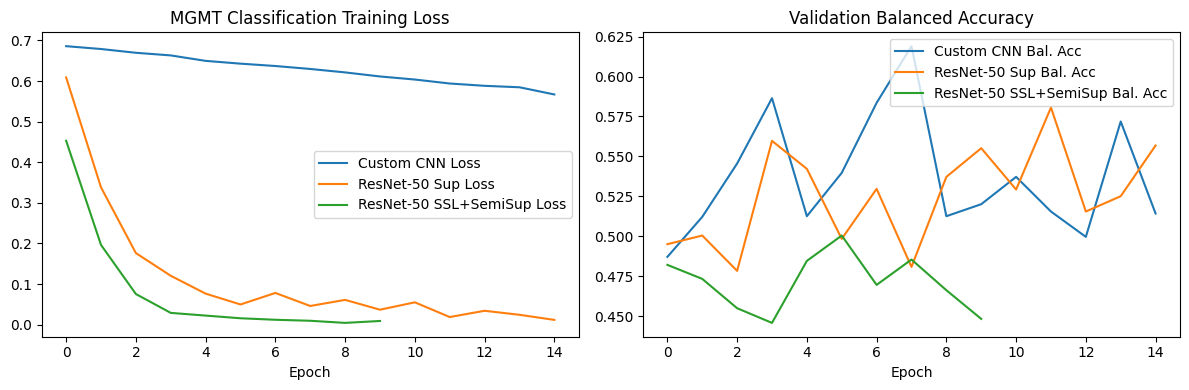

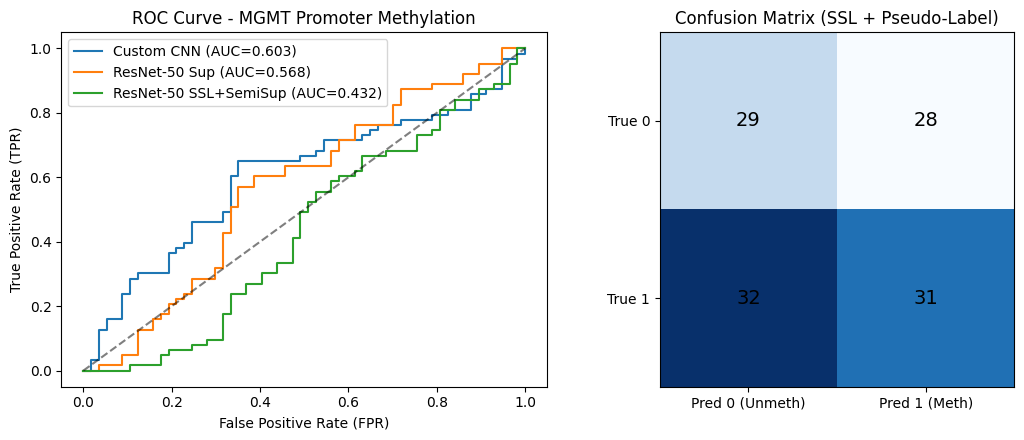

[RAM] Usata: 4.69 GB / 13.61 GB (37.1%)


In [6]:
# Caricamento diretto da Drive (funziona anche dopo un riavvio del runtime su GPU T4)
df = pd.read_csv(os.path.join(OUT_DIR, "dataset_splits_5fold.csv"))
ROI_DRIVE_FILE = os.path.join(OUT_DIR, "patient_rois_128.npz")
assert os.path.exists(ROI_DRIVE_FILE), "Esegui prima la Cella 4B per generare patient_rois_128.npz su Drive!"

loaded = np.load(ROI_DRIVE_FILE)
patient_rois = {int(k): loaded[k] for k in loaded.files}
print(f"ROI caricate istantaneamente da Drive per {len(patient_rois)} pazienti.")
print_ram()


# 1. Self-Supervised Pre-training (Masked + Denoising Autoencoder) su tutti i 1.384 pazienti
class SSLDataset(Dataset):
    def __init__(self, roi_dict):
        self.items = [sl for slices in roi_dict.values() for sl in slices]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        x = self.items[idx].astype(np.float32)  # (5, 128, 128)
        x_corrupted = x.copy()
        for _ in range(4):
            ry = np.random.randint(0, 128 - 24)
            rx = np.random.randint(0, 128 - 24)
            x_corrupted[:4, ry:ry + 24, rx:rx + 24] = 0.0
        x_corrupted[:4] += np.random.normal(0, 0.05, size=x_corrupted[:4].shape).astype(np.float32)
        return torch.tensor(x_corrupted), torch.tensor(x[:4])


class MGMTResNetClassifier(nn.Module):
    def __init__(self, in_channels=5, dropout_p=0.4, pretrained=True):
        super().__init__()
        weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        backbone = models.resnet50(weights=weights)
        old_conv = backbone.conv1
        new_conv = nn.Conv2d(
            in_channels,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False,
        )
        with torch.no_grad():
            new_conv.weight[:, :3] = old_conv.weight
            new_conv.weight[:, 3:] = old_conv.weight.mean(dim=1, keepdim=True)
        backbone.conv1 = new_conv
        in_features = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.encoder = backbone
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_p),
            nn.Linear(in_features, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p / 2),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.classifier(self.encoder(x)).squeeze(-1)


class CustomCNNMGMT(nn.Module):
    """Baseline CNN 2D custom per confronto nel report."""
    def __init__(self, in_channels=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.fc = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 1))

    def forward(self, x):
        return self.fc(self.features(x)).squeeze(-1)


class SSLMaskedAutoencoder(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = nn.Sequential(
            nn.Linear(2048, 512 * 4 * 4), nn.ReLU(inplace=True), nn.Unflatten(1, (512, 4, 4)),
            nn.ConvTranspose2d(512, 256, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 4, 4, 2, 1),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


ssl_loader = DataLoader(SSLDataset(patient_rois), batch_size=32, shuffle=True, num_workers=0)
mgmt_ssl_model = MGMTResNetClassifier(in_channels=5, pretrained=True).to(DEVICE)
ssl_mae = SSLMaskedAutoencoder(mgmt_ssl_model.encoder).to(DEVICE)
ssl_opt = torch.optim.AdamW(ssl_mae.parameters(), lr=1e-3, weight_decay=1e-4)

for ep in range(1, 13):
    ssl_mae.train()
    tot_loss = 0.0
    for xm, x_target in ssl_loader:
        xm, x_target = xm.to(DEVICE), x_target.to(DEVICE)
        ssl_opt.zero_grad()
        loss = F.mse_loss(ssl_mae(xm), x_target)
        loss.backward()
        ssl_opt.step()
        tot_loss += loss.item() * xm.size(0)
    print(f"[SSL Pre-training 1384 pazienti] Ep {ep:02d}/12 | Reconstruction MSE: {tot_loss / len(ssl_loader.dataset):.4f}")

del ssl_mae, ssl_opt, ssl_loader
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# 2. Fine-tuning + Semi-Supervised Pseudo-Labeling (784 unlabelled) + Valutazione
class MGMTDataset(Dataset):
    def __init__(self, sub_df, roi_dict, augment=False):
        self.samples = []
        self.augment = augment
        for _, row in sub_df.iterrows():
            pid = int(row["ID"])
            label = float(row["MGMT value"])
            weight = float(row["sample_weight"]) if "sample_weight" in row else 1.0
            for sl in roi_dict[pid]:
                self.samples.append((pid, sl, label, weight))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        pid, sl, label, weight = self.samples[idx]
        x = sl.astype(np.float32)
        if self.augment and random.random() < 0.5:
            x = np.flip(x, axis=2).copy()
        return pid, torch.tensor(x), torch.tensor(label, dtype=torch.float32), torch.tensor(weight, dtype=torch.float32)


@torch.no_grad()
def predict_patients_mgmt(model, pids, roi_dict):
    model.eval()
    probs_out = {}
    for pid in pids:
        batch = torch.tensor(roi_dict[int(pid)].astype(np.float32), device=DEVICE)
        probs_out[int(pid)] = float(torch.sigmoid(model(batch)).mean().item())
    return probs_out


def train_and_eval_mgmt(
    model, fold=0, epochs=15, lr=3e-4, extra_unlabelled_df=None, save_name=None
):
    labeled_df = df[df["MGMT value"].notna()].copy().reset_index(drop=True)
    labeled_df["sample_weight"] = 1.0
    tr_df = labeled_df[labeled_df["fold"] != fold].copy()
    va_df = labeled_df[labeled_df["fold"] == fold].copy()

    if extra_unlabelled_df is not None and len(extra_unlabelled_df) > 0:
        tr_df = pd.concat([tr_df, extra_unlabelled_df], ignore_index=True)

    tr_loader = DataLoader(MGMTDataset(tr_df, patient_rois, augment=True), batch_size=24, shuffle=True, num_workers=0)
    va_loader = DataLoader(MGMTDataset(va_df, patient_rois, augment=False), batch_size=24, shuffle=False, num_workers=0)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
    criterion = nn.BCEWithLogitsLoss(reduction="none")

    history = {"train_loss": [], "val_bal_acc": []}
    best_ba = -1.0
    best_preds = None

    for ep in range(1, epochs + 1):
        model.train()
        tr_loss = 0.0
        for _, x, y, w in tr_loader:
            x, y, w = x.to(DEVICE), y.to(DEVICE), w.to(DEVICE)
            optimizer.zero_grad()
            loss = (criterion(model(x), y) * w).mean()
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * x.size(0)

        model.eval()
        pid_probs, pid_true = {}, {}
        with torch.no_grad():
            for pids, x, y, _ in va_loader:
                probs = torch.sigmoid(model(x.to(DEVICE))).cpu().numpy()
                for pid, p, yt in zip(pids.numpy(), probs, y.numpy()):
                    pid_probs.setdefault(int(pid), []).append(float(p))
                    pid_true[int(pid)] = int(yt)

        y_true = np.array([pid_true[k] for k in pid_true])
        y_prob = np.array([np.mean(pid_probs[k]) for k in pid_true])
        y_pred = (y_prob >= 0.5).astype(int)
        ba = balanced_accuracy_score(y_true, y_pred)

        history["train_loss"].append(tr_loss / len(tr_loader.dataset))
        history["val_bal_acc"].append(ba)

        if ba > best_ba:
            best_ba = ba
            best_preds = (y_true, y_prob, y_pred)
            if save_name is not None:
                torch.save(model.state_dict(), os.path.join(OUT_DIR, save_name))

    y_true, y_prob, y_pred = best_preds
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    metrics = {
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1_Score": f1_score(y_true, y_pred),
        "Sensitivity": tp / (tp + fn + 1e-8),
        "Specificity": tn / (tn + fp + 1e-8),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Confusion_Matrix": np.array([[tn, fp], [fn, tp]]),
    }
    return metrics, history, (y_true, y_prob)


# A) Baseline Custom CNN (solo 600 labelled)
metrics_cnn, hist_cnn, roc_cnn = train_and_eval_mgmt(
    CustomCNNMGMT(in_channels=5).to(DEVICE), fold=0, epochs=15, lr=5e-4, save_name="best_mgmt_cnn_fold0.pth"
)

# B) ResNet-50 Supervised (solo 600 labelled)
metrics_sup, hist_sup, roc_sup = train_and_eval_mgmt(
    MGMTResNetClassifier(in_channels=5, pretrained=True).to(DEVICE), fold=0, epochs=15, lr=3e-4, save_name="best_mgmt_sup_fold0.pth"
)

# C1) Fine-tuning SSL ResNet-50 sui 600 labelled -> genera pseudo-label ad alta confidenza sui 784 unlabelled
metrics_ssl_s1, _, _ = train_and_eval_mgmt(
    mgmt_ssl_model, fold=0, epochs=12, lr=2e-4, save_name="best_mgmt_ssl_s1_fold0.pth"
)
mgmt_ssl_model.load_state_dict(torch.load(os.path.join(OUT_DIR, "best_mgmt_ssl_s1_fold0.pth"), map_location=DEVICE))

unlabelled_df = df[df["MGMT value"].isna()].copy()
unlab_probs = predict_patients_mgmt(mgmt_ssl_model, unlabelled_df["ID"].tolist(), patient_rois)
pseudo_rows = []
for _, row in unlabelled_df.iterrows():
    p = unlab_probs[int(row["ID"])]
    if p >= 0.85 or p <= 0.15:
        r = row.copy()
        r["MGMT value"] = 1.0 if p >= 0.85 else 0.0
        r["sample_weight"] = 0.5
        pseudo_rows.append(r)

pseudo_df = pd.DataFrame(pseudo_rows)
print(f"Pseudo-label ad alta confidenza selezionate dai 784 unlabelled: {len(pseudo_df)}")

# C2) Fine-tuning finale SSL + Semi-Supervised Pseudo-Labeling
metrics_ssl, hist_ssl, roc_ssl = train_and_eval_mgmt(
    mgmt_ssl_model,
    fold=0,
    epochs=10,
    lr=1e-4,
    extra_unlabelled_df=pseudo_df,
    save_name="best_mgmt_ssl_fold0.pth",
)
mgmt_ssl_model.load_state_dict(torch.load(os.path.join(OUT_DIR, "best_mgmt_ssl_fold0.pth"), map_location=DEVICE))

df_task2 = pd.DataFrame([
    {"Model": "Custom CNN (Supervised)", **{k: v for k, v in metrics_cnn.items() if k != "Confusion_Matrix"}},
    {"Model": "ResNet-50 ROI (Supervised)", **{k: v for k, v in metrics_sup.items() if k != "Confusion_Matrix"}},
    {"Model": "ResNet-50 ROI (SSL + Pseudo-Label)", **{k: v for k, v in metrics_ssl.items() if k != "Confusion_Matrix"}},
])
df_task2.to_csv(os.path.join(OUT_DIR, "task2_metrics_comparison.csv"), index=False)

print("\n=== TABELLA RISULTATI TASK 2 (MGMT CLASSIFICATION) ===")
print(df_task2.to_string(index=False))
print("Confusion Matrix (SSL + Pseudo-Label):\n", metrics_ssl["Confusion_Matrix"])

# Grafici Appendice: Curve Loss e Balanced Accuracy per epoca
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist_cnn["train_loss"], label="Custom CNN Loss")
ax1.plot(hist_sup["train_loss"], label="ResNet-50 Sup Loss")
ax1.plot(hist_ssl["train_loss"], label="ResNet-50 SSL+SemiSup Loss")
ax1.set_title("MGMT Classification Training Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(hist_cnn["val_bal_acc"], label="Custom CNN Bal. Acc")
ax2.plot(hist_sup["val_bal_acc"], label="ResNet-50 Sup Bal. Acc")
ax2.plot(hist_ssl["val_bal_acc"], label="ResNet-50 SSL+SemiSup Bal. Acc")
ax2.set_title("Validation Balanced Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "appendix_cls_curves.png"), dpi=200)
plt.show()

# Grafico Results: ROC Curves + Confusion Matrix
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for name, (yt, yp), m_dict in [
    ("Custom CNN", roc_cnn, metrics_cnn),
    ("ResNet-50 Sup", roc_sup, metrics_sup),
    ("ResNet-50 SSL+SemiSup", roc_ssl, metrics_ssl),
]:
    fpr, tpr, _ = roc_curve(yt, yp)
    ax1.plot(fpr, tpr, label=f"{name} (AUC={m_dict['ROC_AUC']:.3f})")
ax1.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax1.set_title("ROC Curve - MGMT Promoter Methylation")
ax1.set_xlabel("False Positive Rate (FPR)")
ax1.set_ylabel("True Positive Rate (TPR)")
ax1.legend()

cm = metrics_ssl["Confusion_Matrix"]
ax2.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax2.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14, color="black")
ax2.set_xticks([0, 1]); ax2.set_xticklabels(["Pred 0 (Unmeth)", "Pred 1 (Meth)"])
ax2.set_yticks([0, 1]); ax2.set_yticklabels(["True 0", "True 1"])
ax2.set_title("Confusion Matrix (SSL + Pseudo-Label)")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "results_mgmt_roc_cm.png"), dpi=200)
plt.show()
print_ram()

## Cella 6: Task 3 - Explainability (XAI) su Segmentazione e Classificazione + Analisi Critica
*Autosufficiente: ricarica automaticamente i pesi salvati su Drive (`best_seg_manet_fold0.pth` e `best_mgmt_ssl_fold0.pth`) se eseguito dopo un riavvio.*

[XAI Seg - ID 7] Entropia MC-Dropout -> Voxel Errati: 0.6002 vs Corretti: 0.0138
[XAI Seg - ID 15] Entropia MC-Dropout -> Voxel Errati: 0.7269 vs Corretti: 0.0490


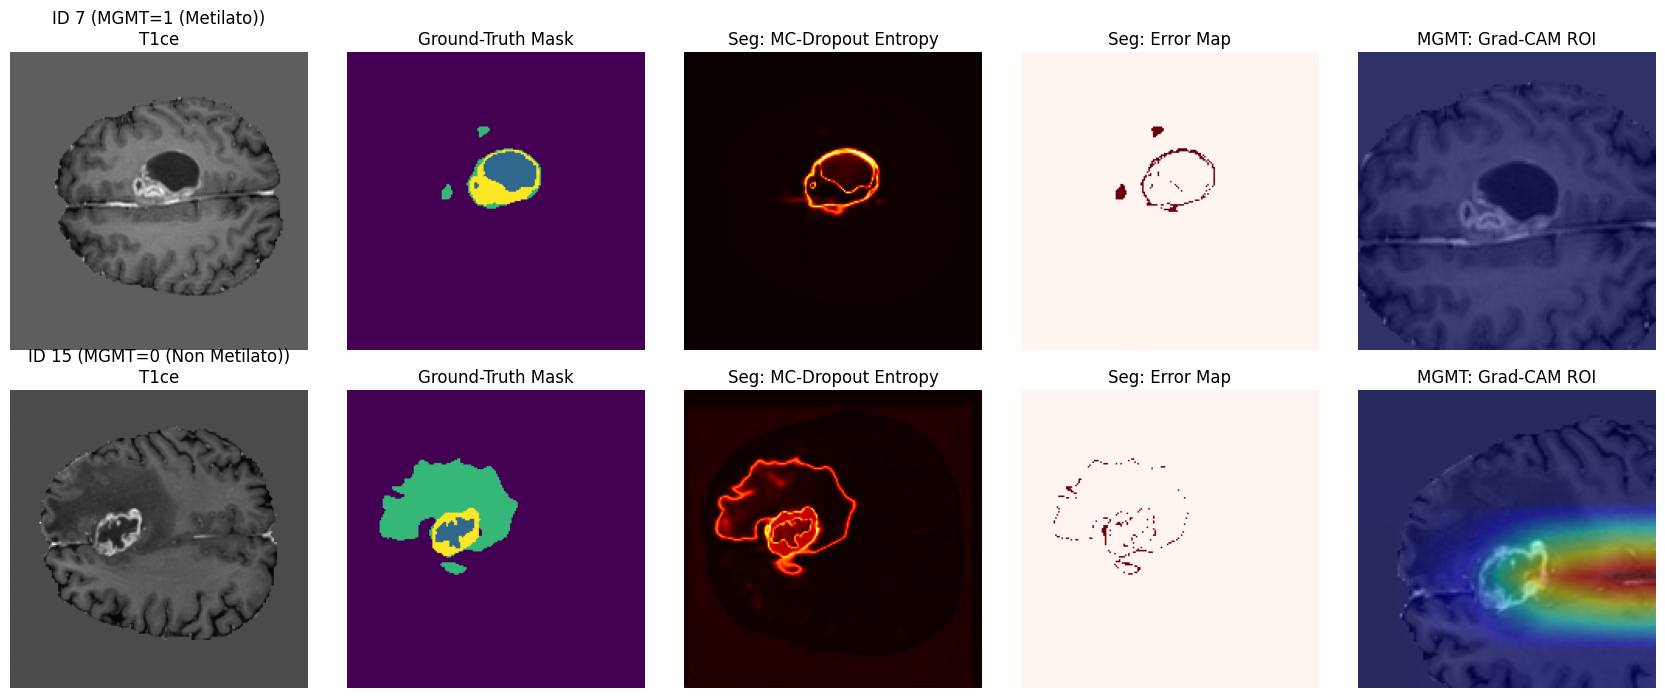


=== XAI: IMPATTO MEDIO ABLAZIONE CANALI SULLA PREDIZIONE MGMT ===
Canale T1              -> Variazione media |ΔP|: 0.1200 ± 0.2028
Canale T1ce            -> Variazione media |ΔP|: 0.1368 ± 0.2101
Canale T2              -> Variazione media |ΔP|: 0.2227 ± 0.2942
Canale FLAIR           -> Variazione media |ΔP|: 0.2456 ± 0.2975
Canale Tumor_ROI_Mask  -> Variazione media |ΔP|: 0.0552 ± 0.0970


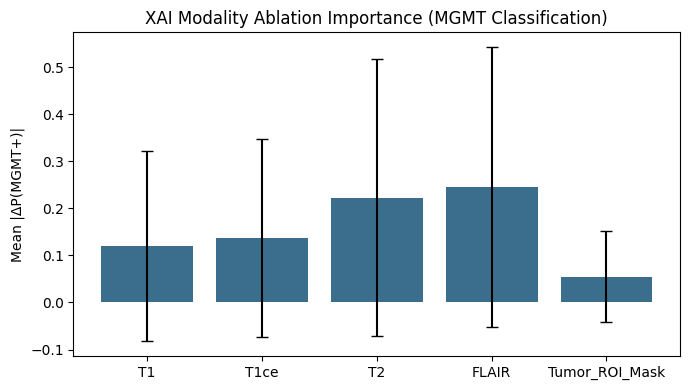

[RAM] Usata: 4.78 GB / 13.61 GB (37.7%)


In [7]:
# Caricamento automatico da Drive se la cella viene eseguita in una nuova sessione
if "df" not in globals():
    df = pd.read_csv(os.path.join(OUT_DIR, "dataset_splits_5fold.csv"))

if "patient_rois" not in globals():
    loaded = np.load(os.path.join(OUT_DIR, "patient_rois_128.npz"))
    patient_rois = {int(k): loaded[k] for k in loaded.files}

if "manet_model" not in globals():
    manet_model = load_saved_seg("manet", os.path.join(OUT_DIR, "best_seg_manet_fold0.pth"))

if "mgmt_ssl_model" not in globals():
    mgmt_ssl_model = MGMTResNetClassifier(in_channels=5, pretrained=False).to(DEVICE)
    mgmt_ssl_model.load_state_dict(torch.load(os.path.join(OUT_DIR, "best_mgmt_ssl_fold0.pth"), map_location=DEVICE))
    mgmt_ssl_model.eval()


# 1. XAI sulla Segmentazione: Monte Carlo Dropout (Incertezza Pixel-Wise) + Correlazione con Errore
def mc_dropout_uncertainty(model, x_slice_tensor, n_samples=20):
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.Dropout, nn.Dropout2d)):
            m.train()  # Attiva il campionamento stocastico sui layer Dropout2d

    probs_list = []
    with torch.no_grad():
        for _ in range(n_samples):
            probs_list.append(torch.softmax(model(x_slice_tensor), dim=1))

    model.eval()
    mean_probs = torch.stack(probs_list, dim=0).mean(dim=0)
    entropy = -torch.sum(mean_probs * torch.log(mean_probs + 1e-8), dim=1)
    return mean_probs.squeeze(0).cpu().numpy(), entropy.squeeze().cpu().numpy()


# 2. XAI sulla Classificazione MGMT: Grad-CAM + Modality Ablation Importance
class GradCAM2D:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(lambda m, i, o: setattr(self, "activations", o.detach()))
        target_layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "gradients", go[0].detach()))

    def generate(self, x_tensor):
        self.model.eval()
        logit = self.model(x_tensor)
        self.model.zero_grad()
        logit.sum().backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x_tensor.shape[2:], mode="bilinear", align_corners=False)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.squeeze().cpu().numpy()


gradcam = GradCAM2D(mgmt_ssl_model, mgmt_ssl_model.encoder.layer4)

# Analisi XAI visiva e quantitativa su due pazienti del validation set (un MGMT=1 e un MGMT=0)
val_both = df[(df["fold"] == 0) & df["has_mask"] & df["MGMT value"].notna()]
pid_pos = int(val_both[val_both["MGMT value"] == 1].iloc[0]["ID"])
pid_neg = int(val_both[val_both["MGMT value"] == 0].iloc[0]["ID"])

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for row_i, (pid_xai, label_str) in enumerate([(pid_pos, "MGMT=1 (Metilato)"), (pid_neg, "MGMT=0 (Non Metilato)")]):
    img_4d, mask_3d, _, _ = load_and_normalize_patient(pid_xai, has_mask=True)
    img_4d, mask_3d = center_crop_or_pad_4d(img_4d, mask_3d, target_hw=192)
    z_max = int(np.argmax((mask_3d > 0).sum(axis=(1, 2))))
    x_sl = torch.tensor(img_4d[:, z_max][None], dtype=torch.float32, device=DEVICE)

    mean_p, uncert_map = mc_dropout_uncertainty(manet_model, x_sl, n_samples=20)
    pred_sl = mean_p.argmax(axis=0)
    error_map = (pred_sl != mask_3d[z_max]).astype(float)

    err_entropy = float(uncert_map[error_map == 1].mean()) if np.any(error_map == 1) else 0.0
    corr_entropy = float(uncert_map[error_map == 0].mean())
    print(f"[XAI Seg - ID {pid_xai}] Entropia MC-Dropout -> Voxel Errati: {err_entropy:.4f} vs Corretti: {corr_entropy:.4f}")

    roi_sample = torch.tensor(patient_rois[pid_xai][0][None], dtype=torch.float32, device=DEVICE)
    cam_map = gradcam.generate(roi_sample)

    axes[row_i, 0].imshow(img_4d[1, z_max], cmap="gray")
    axes[row_i, 0].set_title(f"ID {pid_xai} ({label_str})\nT1ce")

    axes[row_i, 1].imshow(mask_3d[z_max], cmap="viridis", vmin=0, vmax=3)
    axes[row_i, 1].set_title("Ground-Truth Mask")

    axes[row_i, 2].imshow(uncert_map, cmap="hot")
    axes[row_i, 2].set_title("Seg: MC-Dropout Entropy")

    axes[row_i, 3].imshow(error_map, cmap="Reds")
    axes[row_i, 3].set_title("Seg: Error Map")

    axes[row_i, 4].imshow(roi_sample[0, 1].cpu(), cmap="gray")
    axes[row_i, 4].imshow(cam_map, cmap="jet", alpha=0.45)
    axes[row_i, 4].set_title("MGMT: Grad-CAM ROI")

    for c_i in range(5):
        axes[row_i, c_i].axis("off")

    del img_4d, mask_3d

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "results_xai_analysis.png"), dpi=200)
plt.show()

# Analisi Quantitativa XAI: Importanza delle singole modalità MRI nella classificazione MGMT
channel_names = ["T1", "T1ce", "T2", "FLAIR", "Tumor_ROI_Mask"]
val_mgmt_pids = df[(df["fold"] == 0) & df["MGMT value"].notna()]["ID"].tolist()
base_probs = predict_patients_mgmt(mgmt_ssl_model, val_mgmt_pids, patient_rois)

ablation_rows = []
print("\n=== XAI: IMPATTO MEDIO ABLAZIONE CANALI SULLA PREDIZIONE MGMT ===")
for ch_idx, ch_name in enumerate(channel_names):
    deltas = []
    for pid in val_mgmt_pids:
        rois_mod = patient_rois[int(pid)].copy().astype(np.float32)
        rois_mod[:, ch_idx, :, :] = 0.0
        with torch.no_grad():
            p_abl = float(torch.sigmoid(mgmt_ssl_model(torch.tensor(rois_mod, device=DEVICE))).mean().item())
        deltas.append(abs(base_probs[int(pid)] - p_abl))
    mean_d = float(np.mean(deltas))
    std_d = float(np.std(deltas))
    ablation_rows.append({"Channel": ch_name, "Mean_Delta_Prob": mean_d, "Std_Delta_Prob": std_d})
    print(f"Canale {ch_name:15s} -> Variazione media |ΔP|: {mean_d:.4f} ± {std_d:.4f}")

df_ablation = pd.DataFrame(ablation_rows)
df_ablation.to_csv(os.path.join(OUT_DIR, "xai_modality_ablation.csv"), index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(df_ablation["Channel"], df_ablation["Mean_Delta_Prob"], yerr=df_ablation["Std_Delta_Prob"], capsize=4, color="#3b6e8c")
ax.set_ylabel("Mean |ΔP(MGMT+)|")
ax.set_title("XAI Modality Ablation Importance (MGMT Classification)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "results_xai_ablation.png"), dpi=200)
plt.show()
print_ram()

## Cella 7: Script di Inferenza Standalone per il Test Set (Finestra 24h)
*Esegue l'inferenza end-to-end sui pazienti del Test Set (senza label), ripristina la codifica originale BraTS (`3 -> 4`) e l'orientamento NIfTI `(H, W, D)` salvando `seg.nii.gz` per ogni paziente e `test_mgmt_predictions.csv`.*

In [ ]:
def run_test_inference(test_img_dir, output_submission_dir):
    """
    Carica i pesi salvati su Drive, genera le maschere 3D seg.nii.gz rimappando
    3 -> 4 (formato originale BraTS [0, 1, 2, 4]) e salva il CSV delle predizioni MGMT.
    """
    os.makedirs(output_submission_dir, exist_ok=True)

    seg_net = load_saved_seg("manet", os.path.join(OUT_DIR, "best_seg_manet_fold0.pth"))

    cls_net = MGMTResNetClassifier(in_channels=5, pretrained=False).to(DEVICE)
    cls_net.load_state_dict(torch.load(os.path.join(OUT_DIR, "best_mgmt_ssl_fold0.pth"), map_location=DEVICE))
    cls_net.eval()

    test_pids = sorted([
        d for d in os.listdir(test_img_dir)
        if os.path.isdir(os.path.join(test_img_dir, d))
    ])
    mgmt_rows = []

    for pid in tqdm(test_pids, desc="Inferenza Test Set"):
        p_folder = os.path.join(test_img_dir, pid)
        channels = []
        ref_nii = nib.load(os.path.join(p_folder, "t1.nii.gz"))

        for mod in MODALITIES:
            vol = nib.load(os.path.join(p_folder, f"{mod}.nii.gz")).get_fdata().astype(np.float32)
            bm = vol > 0
            if np.any(bm):
                vol[bm] = (vol[bm] - vol[bm].mean()) / (vol[bm].std() + 1e-8)
            vol[~bm] = 0.0
            channels.append(np.transpose(vol, (2, 0, 1)))  # (D, H, W)
        img_4d = np.stack(channels, axis=0)  # (4, D, H, W)

        # 1. Predizione 3D e ripristino orientamento (H, W, D) + codifica originale BraTS [0, 1, 2, 4]
        pred_3d = predict_3d_volume(seg_net, img_4d)
        pred_3d[pred_3d == 3] = 4
        pred_orig_orient = np.transpose(pred_3d, (1, 2, 0)).astype(np.uint8)

        out_p_dir = os.path.join(output_submission_dir, pid)
        os.makedirs(out_p_dir, exist_ok=True)
        nib.save(
            nib.Nifti1Image(pred_orig_orient, ref_nii.affine, ref_nii.header),
            os.path.join(out_p_dir, "seg.nii.gz"),
        )

        # 2. Predizione MGMT a livello di paziente (passando img_dir=test_img_dir)
        rois = extract_patient_roi_slices(pid, seg_net, img_dir=test_img_dir, top_k=5)
        batch_roi = torch.tensor(rois.astype(np.float32), device=DEVICE)
        with torch.no_grad():
            prob = float(torch.sigmoid(cls_net(batch_roi)).mean().item())

        mgmt_rows.append({
            "ID": int(pid),
            "MGMT value": int(prob >= 0.5),
            "MGMT_prob": round(prob, 5),
        })

        del img_4d, pred_3d, pred_orig_orient, rois
        gc.collect()

    pd.DataFrame(mgmt_rows).to_csv(os.path.join(output_submission_dir, "test_mgmt_predictions.csv"), index=False)
    print(f"Inferenza completata per {len(test_pids)} pazienti in: {output_submission_dir}")


# Esempio di utilizzo quando verrà rilasciato il test set (finestra 24h):
# run_test_inference(
#     test_img_dir=os.path.join(BASE_DIR, "test_images"),
#     output_submission_dir=os.path.join(BASE_DIR, "test_submission"),
# )